**Customer Churn & Sales Trends Analysis**

Dataset gathered from Kaggle



In [48]:
import pandas as pd     #importing libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df=pd.read_csv("online_retail.csv") #importing records

In [50]:
#Displaying First five Records
print("=="*70)
print("First Five Records")
print("=="*70)
print(df.head(5).to_string(index=False))
print("=="*70)
print("Last Five Records")
print("=="*70)
print(df.tail(5).to_string(index=False))

First Five Records
InvoiceNo StockCode                         Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0 United Kingdom
   536365     71053                 WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
   536365    84406B      CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75     17850.0 United Kingdom
   536365    84029G KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
   536365    84029E      RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
Last Five Records
InvoiceNo StockCode                     Description  Quantity         InvoiceDate  UnitPrice  CustomerID Country
   581587     22613     PACK OF 20 SPACEBOY NAPKINS        12 2011-12-09 12:50:00       0.85     12680.0  

In [51]:
#Dataset Dimensions
rows,columns=df.shape
print("=="*70)
print("Dataset Dimensions")
print("=="*70)
print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")

Dataset Dimensions
Number of rows: 541909
Number of columns: 8


In [52]:
#finding missing records
print("=="*70)
print("Missing Records")
print("=="*70)
print(df.isnull().sum())

Missing Records
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [53]:
print("=="*70)
print(df.describe(include="all"))
print("=="*70)


       InvoiceNo StockCode                         Description       Quantity  \
count     541909    541909                              540455  541909.000000   
unique     25900      4070                                4223            NaN   
top       573585    85123A  WHITE HANGING HEART T-LIGHT HOLDER            NaN   
freq        1114      2313                                2369            NaN   
mean         NaN       NaN                                 NaN       9.552250   
std          NaN       NaN                                 NaN     218.081158   
min          NaN       NaN                                 NaN  -80995.000000   
25%          NaN       NaN                                 NaN       1.000000   
50%          NaN       NaN                                 NaN       3.000000   
75%          NaN       NaN                                 NaN      10.000000   
max          NaN       NaN                                 NaN   80995.000000   

                InvoiceDate

In [54]:
print("=="*70)
print(df.duplicated().sum())
print("=="*70)

5268


In [55]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [56]:

df["Month"] = df["InvoiceDate"].dt.month
df["Month_Name"] = df["InvoiceDate"].dt.month_name()
df["Weekday"] = df["InvoiceDate"].dt.day_name()
df["Quarter"] = df["InvoiceDate"].dt.quarter
df["Year"] = df["InvoiceDate"].dt.year

In [57]:
df[["InvoiceDate", "Month", "Month_Name",
    "Weekday", "Quarter", "Year"]].head()

,InvoiceDate,Month,Month_Name,Weekday,Quarter,Year
0,2010-12-01 08:26:00,12,December,Wednesday,4,2010
1,2010-12-01 08:26:00,12,December,Wednesday,4,2010
2,2010-12-01 08:26:00,12,December,Wednesday,4,2010
3,2010-12-01 08:26:00,12,December,Wednesday,4,2010
4,2010-12-01 08:26:00,12,December,Wednesday,4,2010


In [58]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
monthly_sales = sales_df.groupby(
    ["Year", "Month"]
)["Revenue"].sum().reset_index()
monthly_sales["MoM_Growth"] = (
    monthly_sales["Revenue"].pct_change() * 100
)
print(monthly_sales)

    Year  Month      Revenue  MoM_Growth
0   2010     12   823746.140         NaN
1   2011      1   691364.560  -16.070677
2   2011      2   523631.890  -24.261103
3   2011      3   717639.360   37.050354
4   2011      4   537808.621  -25.058650
5   2011      5   770536.020   43.273274
6   2011      6   761739.900   -1.141559
7   2011      7   719221.191   -5.581788
8   2011      8   759138.380    5.550057
9   2011      9  1058590.172   39.446272
10  2011     10  1154979.300    9.105424
11  2011     11  1509496.330   30.694665
12  2011     12   638792.680  -57.681733


In [59]:
#Q1. Which products generate the highest revenue?
product_sales = sales_df.groupby("Description")["Revenue"].sum().reset_index()
product_sales.head(10)

,Description,Revenue
0,4 PURPLE FLOCK DINNER CANDLES,290.80
1,50'S CHRISTMAS GIFT BAG LARGE,2343.63
2,DOLLY GIRL BEAKER,2891.25
3,I LOVE LONDON MINI BACKPACK,1628.17
4,I LOVE LONDON MINI RUCKSACK,4.15
5,NINE DRAWER OFFICE TIDY,909.37
6,OVAL WALL MIRROR DIAMANTE,2401.07
7,RED SPOT GIFT BAG LARGE,2107.42
8,SET 2 TEA TOWELS I LOVE LONDON,8100.05
9,SPACEBOY BABY GIFT SET,7758.70


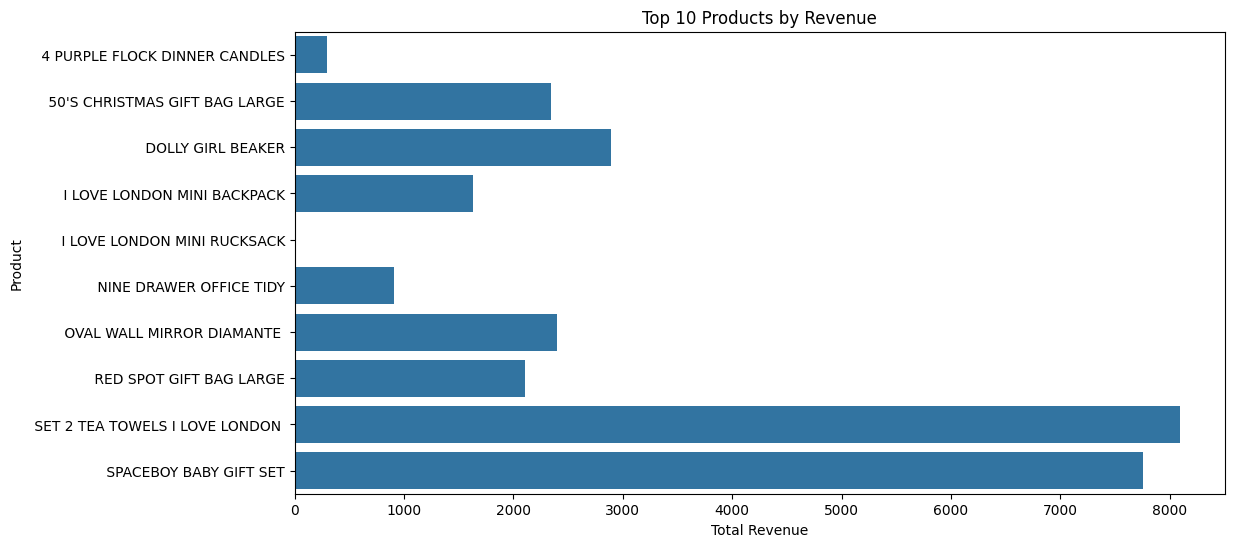

In [60]:
plt.figure(figsize=(12, 6))

sns.barplot(data=product_sales.head(10),
            x="Revenue", y="Description")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.show()

    Year  Month      Revenue
0   2010     12   823746.140
1   2011      1   691364.560
2   2011      2   523631.890
3   2011      3   717639.360
4   2011      4   537808.621
5   2011      5   770536.020
6   2011      6   761739.900
7   2011      7   719221.191
8   2011      8   759138.380
9   2011      9  1058590.172
10  2011     10  1154979.300
11  2011     11  1509496.330
12  2011     12   638792.680
Best Month: Year          2011.00
Month           11.00
Revenue    1509496.33
Name: 11, dtype: float64
Worst Month: Year         2011.00
Month           2.00
Revenue    523631.89
Name: 2, dtype: float64


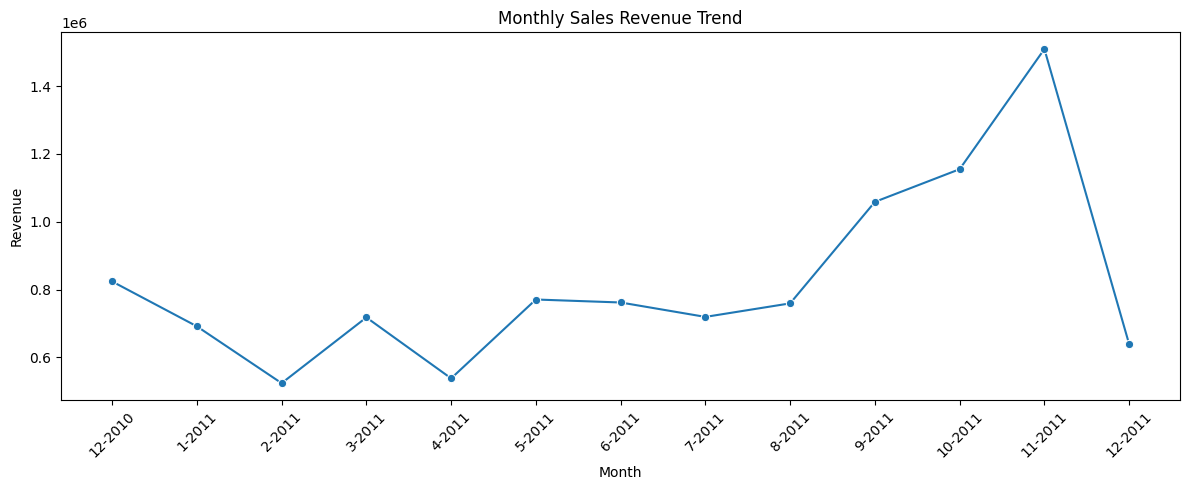

In [61]:
#Q2. Which months generate the highest sales revenue?
monthly_sales = sales_df.groupby(
    ["Year", "Month"]
)["Revenue"].sum().reset_index()

print(monthly_sales)
best_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
worst_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

print("Best Month:", best_month)
print("Worst Month:", worst_month)
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x=monthly_sales.index,
    y="Revenue",
    marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(
    range(len(monthly_sales)),
    monthly_sales["Month"].astype(str) + "-" +
    monthly_sales["Year"].astype(str),
    rotation=45)

plt.tight_layout()
plt.show()

      CustomerID  Total_Spending  Total_Invoices
1689     14646.0       280206.02              73
4201     18102.0       259657.30              60
3728     17450.0       194550.79              46
3008     16446.0       168472.50               2
1879     14911.0       143825.06             201
55       12415.0       124914.53              21
1333     14156.0       117379.63              55
3771     17511.0        91062.38              31
2702     16029.0        81024.84              63
0        12346.0        77183.60               1


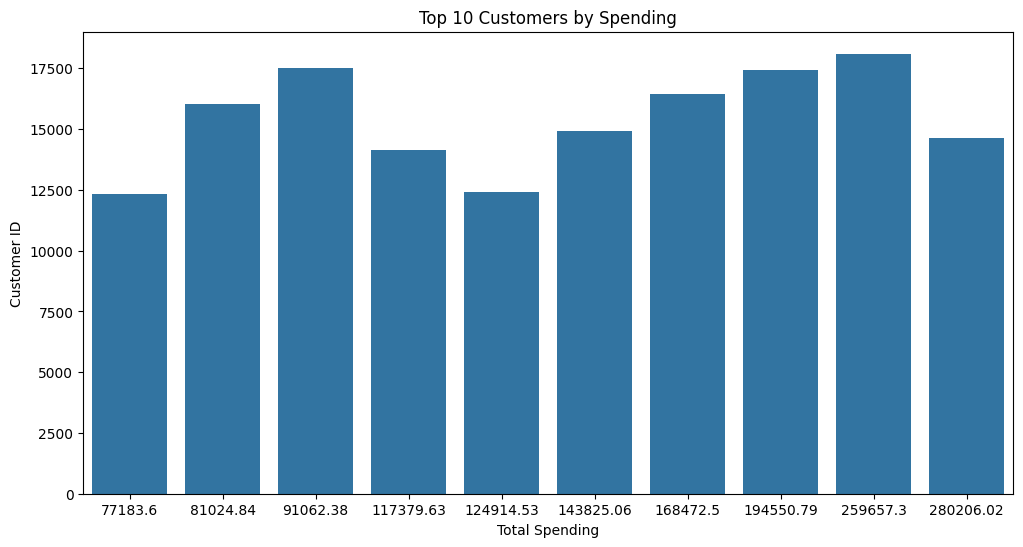

In [62]:
#Q3. Who are the most valuable customers, and how frequently do they purchase?
customer_sales = sales_df.groupby("CustomerID").agg(
    Total_Spending=("Revenue", "sum"),
    Total_Invoices=("InvoiceNo", "nunique")).reset_index()
top_customers = customer_sales.sort_values(
    by="Total_Spending", ascending=False).head(10)

print(top_customers)
plt.figure(figsize=(12, 6))

sns.barplot(data=top_customers,
    x="Total_Spending",
    y="CustomerID")
plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.show()

**Analysis of 80/20 principle (Pareto analysis)**

In [63]:
customer_sales = customer_sales.sort_values(
    by="Total_Spending", ascending=False)
top_10_percent = customer_sales.head(
    int(len(customer_sales) * 0.10))
percentage = (
    top_10_percent["Total_Spending"].sum() /
    customer_sales["Total_Spending"].sum()) * 100
print("Revenue contributed by top 10% customers:", percentage, "%")

Revenue contributed by top 10% customers: 61.334117110121674 %


**Overall Conclusion – E-commerce Sales Analysis**

1. Product Performance (Q1): The analysis identified the top 10 products generating the highest revenue.

2. Monthly Sales Trends (Q2): The monthly revenue analysis helped identify the best- and worst-performing months and understand changes in sales over time.

3. Customer Analysis (Q3): The analysis revealed that the top 10% of customers contribute approximately 61.33% of total revenue.